# Practical 5: Implement the Continuous Bag of Words (CBOW) Model

## Objective:
To design, implement, train, and evaluate a **Continuous Bag of Words (CBOW)** Word2Vec neural network model using a custom text corpus loaded from **`cbow_dataset.csv`**.

---

### Practical Stages:
- **Stage a. Data preparation**
- **Stage b. Generate training data**
- **Stage c. Train model**
- **Stage d. Output**

---

### Theory of CBOW Architecture:
- In the **CBOW model**, the goal is to predict a **target center word** $w_t$ given its **surrounding context words**:
  $$\text{Context: } [w_{t-2}, w_{t-1}, w_{t+1}, w_{t+2}] \longrightarrow \text{Target: } w_t$$
- The context words are projected through an **Embedding / Shared Weight matrix**.
- The embeddings of all context words in the window are **averaged**.
- The averaged representation passes through a **Softmax layer** over the vocabulary to output the probability of each candidate target word.


## Stage a. Data Preparation
In this stage, we load the text dataset from `cbow_dataset.csv`, clean and tokenize sentences, build the unique vocabulary, and create bidirectional mappings between words and integer IDs.

In [1]:
# Stage a: Import libraries
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Input, Dense, Embedding, GlobalAveragePooling1D, Lambda
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical

from sklearn.decomposition import PCA

print("TensorFlow Version:", tf.__version__)


TensorFlow Version: 2.22.0-rc0


In [2]:
# Stage a.1: Load text dataset from CSV
def get_path(filename):
    if os.path.exists(filename):
        return filename
    elif os.path.exists(os.path.join('datasets', filename)):
        return os.path.join('datasets', filename)
    else:
        return filename

cbow_csv_path = get_path('cbow_dataset.csv')
print(f"Loading CBOW text corpus from: {cbow_csv_path}")

df_cbow = pd.read_csv(cbow_csv_path)
print(f"Total sentences loaded: {len(df_cbow)}")
df_cbow.head(10)


Loading CBOW text corpus from: cbow_dataset.csv
Total sentences loaded: 50


,id,text
0,1,deep learning is a subset of machine learning ...
1,2,neural networks learn representations of data ...
2,3,natural language processing enables computers ...
3,4,continuous bag of words model predicts the tar...
4,5,the skip gram model predicts context words giv...
5,6,word embeddings represent words as continuous ...
6,7,similar words are mapped to nearby points in t...
7,8,feedforward neural networks pass information i...
8,9,gradient descent optimizes the weights of the ...
9,10,stochastic gradient descent updates model para...


In [3]:
# Stage a.2: Text Cleaning and Tokenization
def clean_and_tokenize(text):
    # Lowercase and remove punctuation
    text = text.lower()
    text = re.sub(r'[^a-z0-9\s]', '', text)
    tokens = text.strip().split()
    return tokens

# Tokenize all sentences
all_sentences = [clean_and_tokenize(sentence) for sentence in df_cbow['text'].values]

# Flatten token list to inspect vocabulary
all_tokens = [token for sentence in all_sentences for token in sentence]
total_words = len(all_tokens)

# Build Vocabulary and Mappings
vocab_counts = Counter(all_tokens)
vocab = sorted(list(vocab_counts.keys()))
vocab_size = len(vocab)

word_to_id = {word: i for i, word in enumerate(vocab)}
id_to_word = {i: word for i, word in enumerate(vocab)}

print(f"Total running words in corpus: {total_words}")
print(f"Unique Vocabulary Size:        {vocab_size}")
print(f"Sample 15 Vocabulary items:    {vocab[:15]}")


Total running words in corpus: 615
Unique Vocabulary Size:        318
Sample 15 Vocabulary items:    ['a', 'abstraction', 'accuracy', 'accurately', 'across', 'activation', 'acts', 'actual', 'allows', 'an', 'and', 'angle', 'anomalous', 'anomaly', 'approaches']


## Stage b. Generate Training Data

In this stage:
- We set a **context window size** (e.g., `WINDOW_SIZE = 2`).
- For each target word at index $t$, context words are $[t-2, t-1, t+1, t+2]$.
- We construct input pairs: `(context_word_ids, target_word_id)`.
- Convert target words into one-hot vectors.


In [4]:
# Stage b: Generate Context-Target Training Pairs
WINDOW_SIZE = 2  # 2 words before and 2 words after (total 4 context words)

context_data = []
target_data = []

for sentence in all_sentences:
    if len(sentence) < 2 * WINDOW_SIZE + 1:
        continue
    for i in range(WINDOW_SIZE, len(sentence) - WINDOW_SIZE):
        # Extract context words around center word i
        context = (
            sentence[i - WINDOW_SIZE : i] + 
            sentence[i + 1 : i + WINDOW_SIZE + 1]
        )
        target = sentence[i]
        
        # Convert words to integer IDs
        context_ids = [word_to_id[w] for w in context]
        target_id = word_to_id[target]
        
        context_data.append(context_ids)
        target_data.append(target_id)

X = np.array(context_data)
y_int = np.array(target_data)
y = to_categorical(y_int, num_classes=vocab_size)

print(f"Total generated training samples: {len(X)}")
print(f"Shape of Input X (context indices): {X.shape}")
print(f"Shape of Target y (one-hot vectors): {y.shape}")

# Preview sample context-target training pairs
print("\nSample Context -> Target Training Pairs:")
for j in range(5):
    ctx_words = [id_to_word[idx] for idx in X[j]]
    tgt_word = id_to_word[y_int[j]]
    print(f"  Context: {ctx_words} ---> Target: '{tgt_word}'")


Total generated training samples: 415
Shape of Input X (context indices): (415, 4)
Shape of Target y (one-hot vectors): (415, 318)

Sample Context -> Target Training Pairs:
  Context: ['deep', 'learning', 'a', 'subset'] ---> Target: 'is'
  Context: ['learning', 'is', 'subset', 'of'] ---> Target: 'a'
  Context: ['is', 'a', 'of', 'machine'] ---> Target: 'subset'
  Context: ['a', 'subset', 'machine', 'learning'] ---> Target: 'of'
  Context: ['subset', 'of', 'learning', 'based'] ---> Target: 'machine'


## Stage c. Train Model

We implement the CBOW neural network architecture:
1. **Input Layer**: Accepts $2 \times \text{WINDOW\_SIZE} = 4$ integer word IDs.
2. **Embedding Layer**: Projects word IDs into a low-dimensional dense vector space of dimension `embedding_dim = 50`.
3. **Global Average Pooling**: Computes the mean vector of the context word embeddings.
4. **Dense Output Layer**: Softmax layer with `vocab_size` units, predicting probability for each word in the vocabulary.


In [5]:
# Stage c: Define CBOW Neural Network Architecture
embedding_dim = 50
context_length = 2 * WINDOW_SIZE

cbow_model = Sequential([
    # Embedding Layer: maps each token id to embedding_dim vector
    Embedding(input_dim=vocab_size, output_dim=embedding_dim, input_length=context_length, name='embedding_layer'),
    # Average the context embeddings
    GlobalAveragePooling1D(name='average_context'),
    # Dense Softmax classification layer
    Dense(vocab_size, activation='softmax', name='output_softmax')
], name='CBOW_Model')

# Compile model
cbow_model.compile(
    optimizer=Adam(learning_rate=0.01),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

cbow_model.summary()


C:\Users\User\anaconda3\Lib\site-packages\keras\src\layers\core\embedding.py:117: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "CBOW_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_layer (Embedding)          │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ average_context                      │ ?                           │               0 │
│ (GlobalAveragePooling1D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ output_softmax (Dense)               │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [6]:
# Train the CBOW model
epochs = 80
batch_size = 32

print(f"Training CBOW model for {epochs} epochs...")
history = cbow_model.fit(
    X, y,
    epochs=epochs,
    batch_size=batch_size,
    verbose=1
)
print("CBOW Model Training Complete!")


Training CBOW model for 80 epochs...
Epoch 1/80
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - accuracy: 0.0265 - loss: 5.7484
Epoch 2/80
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.1759 - loss: 5.5232 
Epoch 3/80
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1687 - loss: 5.0998 
Epoch 4/80
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1783 - loss: 4.5281 
Epoch 5/80
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.2289 - loss: 3.9282 
Epoch 6/80
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3253 - loss: 3.2461 
Epoch 7/80
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4434 - loss: 2.5634 
Epoch 8/80
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6072 - loss: 1.9520 
Epoch 9/80
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7711 - loss: 1.4548 
Epoch 10/80
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8892 - loss: 1.0784 
Epoch 11/80
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9614 - loss: 0.8028 
Epoch 12/80
13/13 ━━━━━━━━

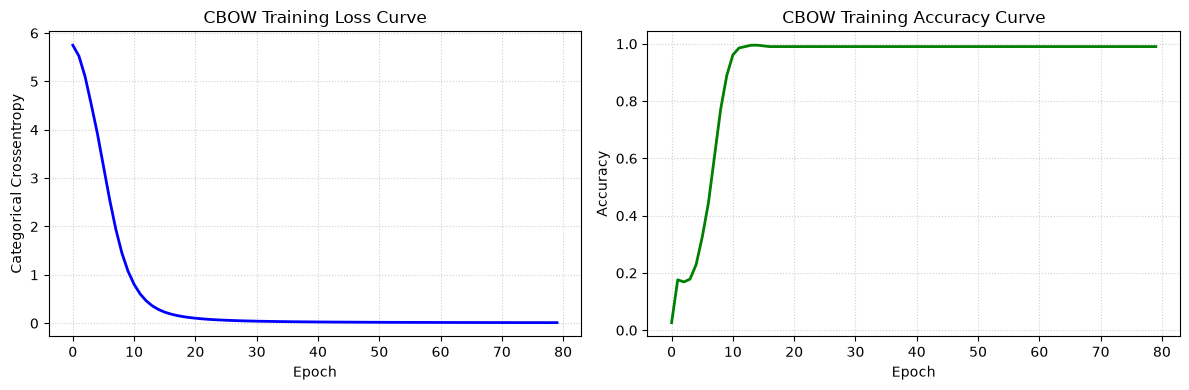

In [7]:
# Plot CBOW Training Loss and Accuracy
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], 'b-', linewidth=2)
plt.title('CBOW Training Loss Curve')
plt.xlabel('Epoch')
plt.ylabel('Categorical Crossentropy')
plt.grid(True, linestyle=':', alpha=0.6)

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], 'g-', linewidth=2)
plt.title('CBOW Training Accuracy Curve')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()


## Stage d. Output

In this final stage:
1. **Target Word Prediction**: Given context words, predict the missing center word.
2. **Embedding Weights Extraction**: Extract learned word vectors from the embedding layer.
3. **Cosine Similarity**: Compute semantic similarity between learned word vectors.
4. **2D PCA Visualization**: Plot learned word vectors in 2D semantic space.


In [8]:
# Stage d.1: Predicting target word given context words
def predict_target_word(context_words, top_k=3):
    # Ensure all context words exist in vocabulary
    valid_words = [w.lower() for w in context_words if w.lower() in word_to_id]
    if len(valid_words) != 2 * WINDOW_SIZE:
        print(f"Error: Please provide exactly {2 * WINDOW_SIZE} valid context words present in vocabulary.")
        return
    
    ctx_ids = np.array([[word_to_id[w] for w in valid_words]])
    predictions = cbow_model.predict(ctx_ids, verbose=0)[0]
    
    top_indices = np.argsort(predictions)[-top_k:][::-1]
    
    print(f"\nContext Words: {valid_words}")
    print("Predicted Target Words (Top Candidates):")
    for rank, idx in enumerate(top_indices, 1):
        word = id_to_word[idx]
        prob = predictions[idx] * 100
        print(f"  {rank}. '{word}' (Probability: {prob:.2f}%)")

# Test prediction with sample context
predict_target_word(['deep', 'learning', 'machine', 'learning'])
predict_target_word(['neural', 'networks', 'representations', 'of'])



Context Words: ['deep', 'learning', 'machine', 'learning']
Predicted Target Words (Top Candidates):
  1. 'for' (Probability: 41.55%)
  2. 'models' (Probability: 41.19%)
  3. 'of' (Probability: 4.82%)

Context Words: ['neural', 'networks', 'representations', 'of']
Predicted Target Words (Top Candidates):
  1. 'learn' (Probability: 99.26%)
  2. 'representations' (Probability: 0.24%)
  3. 'are' (Probability: 0.09%)


In [9]:
# Stage d.2: Extract Learned Word Embeddings
embedding_matrix = cbow_model.get_layer('embedding_layer').get_weights()[0]
print("Learned Embedding Matrix Shape (vocab_size, embedding_dim):", embedding_matrix.shape)

# Helper function to compute cosine similarity
def cosine_similarity(vec_a, vec_b):
    dot = np.dot(vec_a, vec_b)
    norm_a = np.linalg.norm(vec_a)
    norm_b = np.linalg.norm(vec_b)
    if norm_a == 0 or norm_b == 0:
        return 0.0
    return dot / (norm_a * norm_b)

def find_most_similar_words(target_word, top_n=5):
    target_word = target_word.lower()
    if target_word not in word_to_id:
        print(f"Word '{target_word}' not found in vocabulary.")
        return
    
    target_idx = word_to_id[target_word]
    target_vec = embedding_matrix[target_idx]
    
    similarities = []
    for word, idx in word_to_id.items():
        if word == target_word:
            continue
        sim = cosine_similarity(target_vec, embedding_matrix[idx])
        similarities.append((word, sim))
    
    similarities.sort(key=lambda x: x[1], reverse=True)
    
    print(f"\nMost similar words to '{target_word}':")
    for rank, (word, sim) in enumerate(similarities[:top_n], 1):
        print(f"  {rank}. '{word}' -> Cosine Similarity: {sim:.4f}")

# Find similar words
find_most_similar_words('neural')
find_most_similar_words('learning')
find_most_similar_words('data')


Learned Embedding Matrix Shape (vocab_size, embedding_dim): (318, 50)

Most similar words to 'neural':
  1. 'widely' -> Cosine Similarity: 0.6029
  2. 'feedforward' -> Cosine Similarity: 0.5825
  3. 'recurrent' -> Cosine Similarity: 0.5138
  4. 'convolutional' -> Cosine Similarity: 0.5035
  5. 'similar' -> Cosine Similarity: 0.4864

Most similar words to 'learning':
  1. 'unit' -> Cosine Similarity: 0.5155
  2. 'trained' -> Cosine Similarity: 0.5048
  3. 'linguistic' -> Cosine Similarity: 0.4241
  4. 'deep' -> Cosine Similarity: 0.4077
  5. 'linear' -> Cosine Similarity: 0.3941

Most similar words to 'data':
  1. 'detection' -> Cosine Similarity: 0.4952
  2. 'explicit' -> Cosine Similarity: 0.4757
  3. 'like' -> Cosine Similarity: 0.4415
  4. 'hidden' -> Cosine Similarity: 0.4210
  5. 'complex' -> Cosine Similarity: 0.4137


findfont: Failed to find font weight semibold, now using 700.


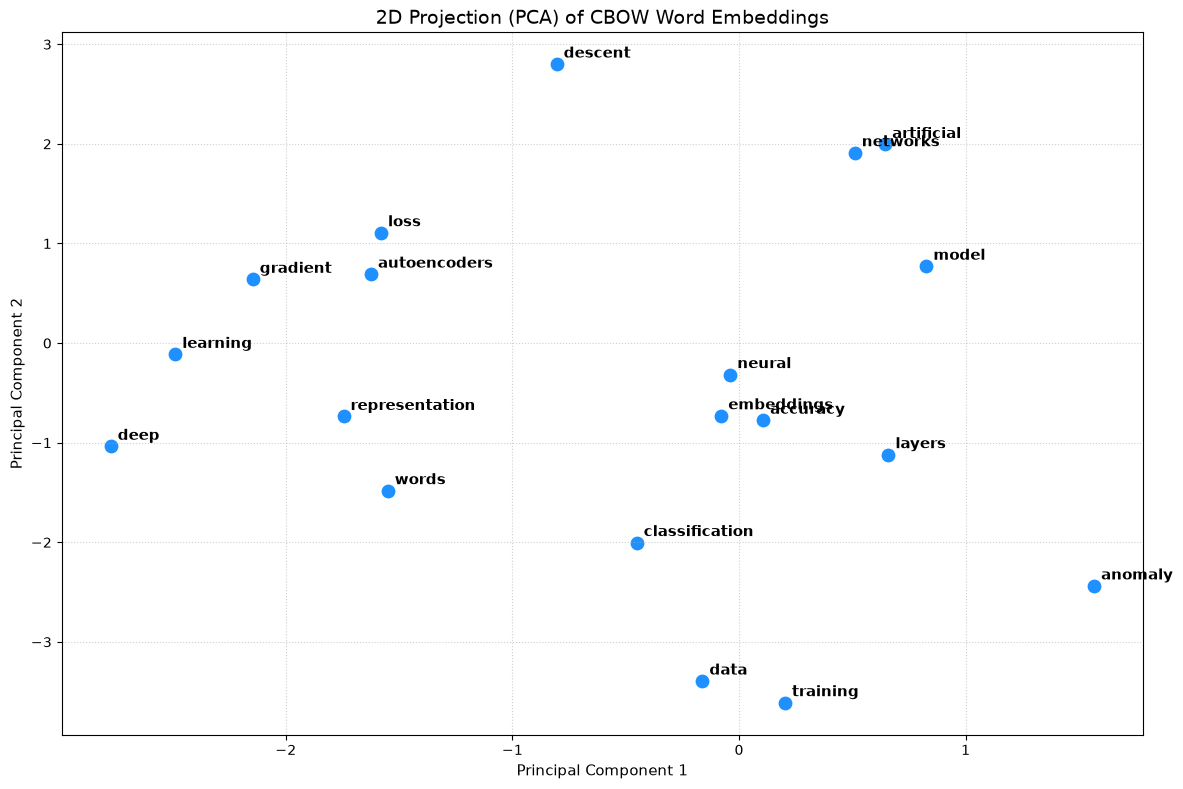

In [10]:
# Stage d.3: 2D Visualization of Word Embeddings using PCA
pca = PCA(n_components=2)
reduced_embeddings = pca.fit_transform(embedding_matrix)

# Select a subset of prominent words to plot cleanly
selected_words = [
    'neural', 'networks', 'deep', 'learning', 'data',
    'words', 'embeddings', 'model', 'training', 'loss',
    'gradient', 'descent', 'artificial', 'classification',
    'accuracy', 'layers', 'representation', 'anomaly', 'autoencoders'
]
selected_words = [w for w in selected_words if w in word_to_id]

plt.figure(figsize=(12, 8))
for word in selected_words:
    idx = word_to_id[word]
    x, y_coord = reduced_embeddings[idx]
    plt.scatter(x, y_coord, color='dodgerblue', s=80)
    plt.annotate(word, xy=(x, y_coord), xytext=(5, 2),
                 textcoords='offset points', ha='left', va='bottom',
                 fontsize=11, fontweight='semibold')

plt.title("2D Projection (PCA) of CBOW Word Embeddings", fontsize=14)
plt.xlabel("Principal Component 1", fontsize=11)
plt.ylabel("Principal Component 2", fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


## Conclusion:
1. **Stage a**: Loaded text corpus from `cbow_dataset.csv`, cleaned, tokenized, and created vocabulary dictionary mappings.
2. **Stage b**: Generated training pairs of context words ($X$) and target words ($y$) with sliding window size of 2.
3. **Stage c**: Built and trained a CBOW architecture with an Embedding layer and Global Average Pooling.
4. **Stage d**: Outputted target word predictions, extracted continuous word vectors, calculated cosine similarities, and projected embeddings in 2D space.
